In [1]:
import pandas as pd
dji = pd.read_csv('DJI.csv')
ufo = pd.read_csv('ufo.csv')

In [2]:
dji.head()

,Date,Value
0,1941,110.96
1,1942,119.40
2,1943,135.89
3,1944,152.32
4,1945,192.91


In [3]:
ufo.head()

,Date,Value
0,1941,1
1,1942,2
2,1943,9
3,1944,9
4,1945,9


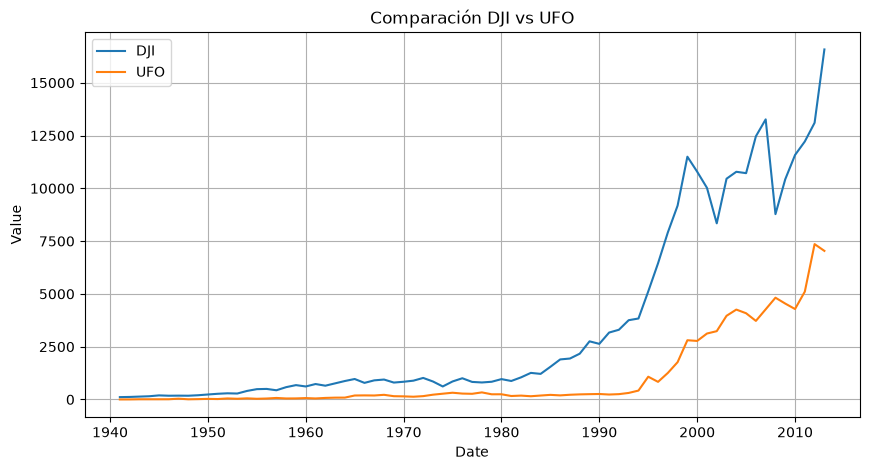

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(dji["Date"], dji["Value"], label="DJI")
plt.plot(ufo["Date"], ufo["Value"], label="UFO")
plt.xlabel("Date")
plt.ylabel("Value")
plt.title("Comparación DJI vs UFO")
plt.legend()
plt.grid(True)
plt.show()

# Correlaciones Espurias

- Dos series con tendencia pueden presentar una alta correlación aún cuando no tinen ninguna relación. (*spurious correlation*) 
- Por ello, en series financieras se analiza la relación de los **rendimientos** y de los **niveles**.

In [5]:
levels = dji.merge(ufo, on="Date", suffixes=("_DJI", "_UFO"))
levels = levels.sort_values(by="Date").reset_index(drop=True)
levels.head()

,Date,Value_DJI,Value_UFO
0,1941,110.96,1
1,1942,119.40,2
2,1943,135.89,9
3,1944,152.32,9
4,1945,192.91,9


## **Cálculo de la correlación**

In [6]:
correlation1 = levels["Value_DJI"].corr(levels["Value_UFO"])
print(f"Correlación entre DJI y UFO: {correlation1:.4f}")

changes = levels.pct_change()
correlation2 = changes["Value_DJI"].corr(changes["Value_UFO"])
print(f"Correlación entre los cambios porcentuales de DJI y UFO: {correlation2:.4f}")   

Correlación entre DJI y UFO: 0.9400
Correlación entre los cambios porcentuales de DJI y UFO: 0.0603


In [7]:
changes.head(20)

,Date,Value_DJI,Value_UFO
0,NaN,NaN,NaN
1,0.000515,0.076063,1.000000
2,0.000515,0.138107,3.500000
3,0.000515,0.120907,0.000000
4,0.000514,0.266478,0.000000
5,0.000514,-0.081437,0.111111
6,0.000514,0.022348,2.700000
7,0.000514,-0.021307,-0.783784
8,0.000513,0.128765,1.000000
9,0.000513,0.176285,0.750000


# Coeficiente de Determinación (R²)
- El **R²** mide que tan bien se ajustan los datos a la recta de regresión.


$$
|\rho_{xy}| = \sqrt{R^2}
$$

In [8]:
import numpy as np
import statsmodels.api as sm

np.random.seed(42)

x = pd.Series(np.random.rand(100), name="x")
y = pd.Series(3*x + np.random.normal(0, 20, 100), name="y")

correlation = x.corr(y)
print(f"Correlación entre x e y: {correlation:.4f}")

X = pd.DataFrame(x)
X = sm.add_constant(X)

model = sm.OLS(y, X)
results = model.fit()

print(results.summary())

Correlación entre x e y: -0.1016
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.010
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     1.022
Date:                Wed, 15 Jul 2026   Prob (F-statistic):              0.315
Time:                        12:31:39   Log-Likelihood:                -430.72
No. Observations:                 100   AIC:                             865.4
Df Residuals:                      98   BIC:                             870.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.30

## Reversión a la Media y Autocorrelación 

In [9]:
msft = pd.read_csv('MSFT.csv')

In [10]:
msft["Date"] = pd.to_datetime(msft["Date"])
msft = msft.set_index("Date")

In [11]:
msft.dtypes

Adj Close    float64
dtype: object

In [12]:
msft = msft.resample(rule='W').last()
returns = msft["Adj Close"].pct_change().dropna()
autocorrelation = returns.autocorr()
print(f"Autocorrelación de los retornos: {autocorrelation:.4f}")

Autocorrelación de los retornos: -0.1568


# Autocorrelación de las Tasas de Interés

In [13]:
daily_rates = pd.read_csv('GS10.csv')
daily_rates.head()

,observation_date,GS10
0,1953-04-01,2.83
1,1953-05-01,3.05
2,1953-06-01,3.11
3,1953-07-01,2.93
4,1953-08-01,2.95


In [14]:
daily_rates.dtypes

observation_date        str
GS10                float64
dtype: object

In [15]:
daily_rates["observation_date"] = pd.to_datetime(daily_rates["observation_date"])
daily_rates = daily_rates.set_index("observation_date")
daily_rates.head()

,GS10
observation_date,
1953-04-01,2.83
1953-05-01,3.05
1953-06-01,3.11
1953-07-01,2.93
1953-08-01,2.95


In [16]:
daily_diff = daily_rates.diff().dropna()
daily_diff.head()

,GS10
observation_date,
1953-05-01,0.22
1953-06-01,0.06
1953-07-01,-0.18
1953-08-01,0.02
1953-09-01,-0.08


In [17]:
autocorrelation_daily_diff = daily_diff["GS10"].autocorr()
print(f"Autocorrelación de los cambios diarios en GS10: {autocorrelation_daily_diff:.4f}")

Autocorrelación de los cambios diarios en GS10: 0.3063


In [18]:
yearly_rates = daily_rates.resample('YE').last()
yearly_diff = yearly_rates.diff().dropna()
autocorrelation_yearly_diff = yearly_diff["GS10"].autocorr()
print(f"Autocorrelación de los cambios anuales en GS10: {autocorrelation_yearly_diff:.4f}")

Autocorrelación de los cambios anuales en GS10: -0.1236
